<a href="https://colab.research.google.com/github/edixonharbey-ctrl/ANALISIS-DE-DIFERENTES-M-TRICAS-DEL-TRASPORTE-MASIVO-TRANSMILENIO-MEDIANTE-MAPREDUCE./blob/main/PROYECTOFINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Análisis de N-Gramas y Sentimientos en Opiniones Hoteleras (`Opiniones_Hoteleras.xlsx`)**

* **Autor(es):** Edixon Harbey Rubiano Robayo y Cristian Alejandro Perdomo Rivas
* **Fecha:** 21 de noviembre de 2026
* **Versión:** 1.0
* **Entorno:** Google Colab (Python 3.x)

## 1. Objetivos del Análisis
1. **Explorar y depurar** un conjunto de reseñas hoteleras, corrigiendo anomalías de lectura y codificación.
2. **Construir un pipeline de preprocesamiento NLP** (normalización, limpieza de ruido, manejo de *stopwords* y *stemming*/lematización) y cuantificar su impacto frente al texto original.
3. **Generar representaciones textuales basadas en n-gramas** (*Count* y *TF-IDF*) y visualizar los patrones lingüísticos más relevantes.
4. **Implementar y comparar enfoques de análisis de sentimientos** (*TextBlob* vs. *scikit-learn*), evaluando su desempeño con métricas estándar, matriz de confusión y un análisis detallado de errores.

## 2. Contexto y Descripción del Dataset
El archivo **`Opiniones_Hoteleras.xlsx`** reúne opiniones de huéspedes sobre alojamientos, hoteles y hostales (ubicación, limpieza, servicio del personal, ruido, comodidades como aire acondicionado/agua caliente y relación precio-calidad).

Al tratarse de texto libre no estructurado sin una columna de etiqueta humana preexistente, el cuaderno aborda primero el **análisis exploratorio y de n-gramas** y, posteriormente, construye un marco de **análisis de sentimientos** que permite contrastar un enfoque basado en polaridad/reglas (*TextBlob*) frente a un modelo supervisado clásico (*scikit-learn*).

## 3. Carga y Exploración Inicial del Dataset
En este paso se importan las librerías base de manipulación de datos y visualización (`pandas`, `numpy`, `matplotlib`, `seaborn`), se carga la hoja `Hoja1` con `header=None` para rescatar la primera reseña ubicada en la cabecera y se repara la codificación *mojibake* (*UTF-8* mal interpretado como *Latin-1* / *CP1252*).

In [2]:
# --- Librerías utilizadas ---
# pandas y numpy: carga, limpieza y cálculo de estadísticas descriptivas
# matplotlib y seaborn: exploración gráfica inicial

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética de gráficos
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")

# 1. Cargar el archivo Excel sin asumir encabezado (para recuperar la fila 0)
ruta_archivo = "Opiniones_Hoteleras.xlsx"
excel_file = pd.ExcelFile(ruta_archivo)
print("Hojas disponibles:", excel_file.sheet_names)

df = pd.read_excel(ruta_archivo, sheet_name="Hoja1", header=None)
df.columns = ["opinion_raw"]


# 2. Función para corregir doble/simple codificación mojibake (CP1252/Latin1 -> UTF-8)
def reparar_codificacion(texto):
    if not isinstance(texto, str):
        return ""
    actual = texto
    for _ in range(3):
        cambiado = False
        for enc in ("cp1252", "latin1"):
            try:
                candidato = actual.encode(enc).decode("utf-8")
                if candidato != actual:
                    actual = candidato
                    cambiado = True
                    break
            except Exception:
                continue
        if not cambiado:
            break
    return actual


df["opinion_corregida"] = df["opinion_raw"].apply(reparar_codificacion)

# 3. Información general y muestra de registros
print(f"\nDimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
print("Valores nulos por columna:\n", df.isnull().sum())
print("Registros duplicados exactos (corregidos):", df["opinion_corregida"].duplicated().sum())

print("\n--- Muestra de los primeros 5 registros ---")
for idx, row in df.head(5).iterrows():
    print(f"[{idx}] {row['opinion_corregida']}\n")

# 4. Estadísticas básicas de longitud (caracteres y palabras)
df["len_chars_raw"] = df["opinion_corregida"].str.len()
df["len_words_raw"] = df["opinion_corregida"].str.split().str.len()

print("--- Estadísticas descriptivas (texto corregido) ---")
print(df[["len_chars_raw", "len_words_raw"]].describe().round(2))

Hojas disponibles: ['Hoja1']

Dimensiones del dataset: 1000 filas x 2 columnas
Valores nulos por columna:
 opinion_raw          0
opinion_corregida    0
dtype: int64
Registros duplicados exactos (corregidos): 99

--- Muestra de los primeros 5 registros ---
[0] único detalle a corregir es la ausencia de cocina para calentar alimentos y un refrigerador... si bien tienen una cocina eléctrica y un microondas lo insuficiente, la vajilla la tienes que solicitar en recepción y no tenían ni tenedores ni cuchillos. el resto espectacular.,,,,

[1] Bueno, en relacion al precio que se paga, ya que es economico para Paris, las habitaciones buenas, los espacios comunes tambien, lo peor son los baños compartidos, las duchas no son buenas y la limpieza mas o menos. Otro detalle no tienen enchufe en todas la camas,,,,

[2] muy limpio y muy bien situado. pero no tiene aire condicionado, ni agua caliente. humilde, si lo que buscas es algo bueno, pero en verano poco recomendable al no tener aire condicion

## 4. Limpieza y Normalización del Texto
Para reducir el ruido léxico sin perder información semántica clave en español, se aplica un pipeline modular que:
1. Convierte el texto a **minúsculas**.
2. Elimina **URLs**, **emojis/símbolos no alfabéticos**, **comas residuales repetidas** (`,,,,`) y **signos de puntuación**.
3. Filtra **stopwords en español** mediante `nltk`, conservando deliberadamente negaciones frecuentes (`no`, `ni`, `sin`, `nada`, `tampoco`, `pero`, `sin embargo`) en una variante controlada para no invertir el sentido de frases como *"no tiene agua caliente"* o *"sin embargo"*.
4. Aplica **stemming en español** con `SnowballStemmer("spanish")` de `nltk` (y muestra cómo integrar `spacy` si se desea lematización morfológica completa).

In [3]:
# --- Librerías utilizadas ---
# re: expresiones regulares para limpiar URLs, puntuación, emojis y ruido
# nltk: tokenización, stopwords en español y stemming (SnowballStemmer)

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

# Descargar recursos necesarios de NLTK (solo la primera vez)
nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# Construir conjunto de stopwords en español preservando palabras de negación/contraste
stop_words_es = set(stopwords.words("spanish"))
palabras_a_conservar = {
    "no",
    "ni",
    "sin",
    "nada",
    "tampoco",
    "nunca",
    "jamas",
    "jamás",
    "pero",
    "aunque",
    "sino",
}
stop_words_filtradas = stop_words_es - palabras_a_conservar

stemmer_es = SnowballStemmer("spanish")


def normalizar_y_limpiar(texto, usar_stemming=True):
    """Limpia ruido, normaliza minúsculas, elimina stopwords y aplica stemming."""
    if not isinstance(texto, str):
        return ""

    # 1. Minúsculas
    texto = texto.lower()

    # 2. Eliminar URLs y correos
    texto = re.sub(r"http\S+|www\.\S+|\S+@\S+", " ", texto)

    # 3. Eliminar secuencias de comas/puntos residuales y caracteres no alfabéticos (preservando acentos y ñ)
    texto = re.sub(r"[,._\-]{2,}", " ", texto)
    texto = re.sub(r"[^a-záéíóúüñ\s]", " ", texto)

    # 4. Colapsar espacios múltiples
    texto = re.sub(r"\s+", " ", texto).strip()

    # 5. Tokenización simple por espacio tras limpieza y filtrado de stopwords
    tokens = [tok for tok in texto.split() if tok not in stop_words_filtradas and len(tok) > 1]

    # 6. Stemming opcional
    if usar_stemming:
        tokens = [stemmer_es.stem(tok) for tok in tokens]

    return " ".join(tokens)


# Generar versión limpia sin stemming (útil para lectura/sentimientos) y con stemming (para n-gramas/modelos)
df["texto_limpio_sin_stem"] = df["opinion_corregida"].apply(
    lambda x: normalizar_y_limpiar(x, usar_stemming=False)
)
df["texto_procesado"] = df["opinion_corregida"].apply(
    lambda x: normalizar_y_limpiar(x, usar_stemming=True)
)

print("Ejemplo de transformación:")
print("Original : ", df["opinion_corregida"].iloc[1])
print("Sin stem : ", df["texto_limpio_sin_stem"].iloc[1])
print("Con stem : ", df["texto_procesado"].iloc[1])

Ejemplo de transformación:
Original :  Bueno, en relacion al precio que se paga, ya que es economico para Paris, las habitaciones buenas, los espacios comunes tambien, lo peor son los baños compartidos, las duchas no son buenas y la limpieza mas o menos. Otro detalle no tienen enchufe en todas la camas,,,,
Sin stem :  bueno relacion precio paga economico paris habitaciones buenas espacios comunes tambien peor baños compartidos duchas no buenas limpieza mas menos detalle no enchufe todas camas
Con stem :  buen relacion preci pag econom paris habit buen espaci comun tambi peor bañ compart duch no buen limpiez mas men detall no enchuf tod cam


## 5. Transformaciones: Tokenización, N-Gramas y Vectorización (`Count` vs. `TF-IDF`)
* **Tokenización y N-gramas:** los unigramas (`(1,1)`) capturan palabras clave aisladas (ej. *limpio*, *ruido*, *recepción*), mientras que los bigramas y trigramas (`(2,3)`) preservan contexto local y construcciones compuestas (ej. *agua caliente*, *aire acondicionado*, *no tiene*).
* **CountVectorizer (`Count`):** cuenta la frecuencia bruta de aparición de cada término o n-grama; es intuitivo para análisis descriptivo de frecuencia, pero favorece términos muy comunes.
* **TfidfVectorizer (`TF-IDF`):** pondera cada término según su frecuencia en la reseña (*TF*) y la inversa de su frecuencia documental (*IDF*), penalizando palabras genéricas y destacando términos más distintivos.

In [4]:
# --- Librerías utilizadas ---
# nltk.tokenize: word_tokenize para inspección explícita de tokens
# sklearn.feature_extraction.text: CountVectorizer y TfidfVectorizer para n-gramas y matrices numéricas

from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Ejemplo explícito de tokenización sobre la primera reseña procesada
muestra_tokens = word_tokenize(df["texto_procesado"].iloc[0], language="spanish")
print("Tokens de ejemplo (registro 0):", muestra_tokens[:15])

# 1. Representación CountVectorizer (unigramas a trigramas)
count_vec = CountVectorizer(ngram_range=(1, 3), min_df=2, max_features=5000)
X_count = count_vec.fit_transform(df["texto_procesado"])

# 2. Representación TfidfVectorizer (unigramas a bigramas)
tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000)
X_tfidf = tfidf_vec.fit_transform(df["texto_procesado"])

print(f"Matriz CountVectorizer: {X_count.shape} (reseñas x n-gramas)")
print(f"Matriz TfidfVectorizer : {X_tfidf.shape} (reseñas x n-gramas)")


def top_ngrams(corpus, ngram_range=(2, 2), top_n=15):
    """Devuelve un DataFrame ordenado con los n-gramas más frecuentes."""
    vec = CountVectorizer(ngram_range=ngram_range, min_df=2)
    matriz = vec.fit_transform(corpus)
    sumas = np.asarray(matriz.sum(axis=0)).ravel()
    vocab = np.array(vec.get_feature_names_out())
    orden = np.argsort(sumas)[::-1][:top_n]
    return pd.DataFrame({"ngram": vocab[orden], "frecuencia": sumas[orden]})


df_top_unigramas = top_ngrams(df["texto_procesado"], ngram_range=(1, 1), top_n=15)
df_top_bigramas = top_ngrams(df["texto_procesado"], ngram_range=(2, 2), top_n=15)
df_top_trigramas = top_ngrams(df["texto_procesado"], ngram_range=(3, 3), top_n=15)

print("\nTop 10 Bigramas (stem):")
print(df_top_bigramas.head(10).to_string(index=False))

Tokens de ejemplo (registro 0): ['unic', 'detall', 'correg', 'ausenci', 'cocin', 'calent', 'aliment', 'refriger', 'si', 'bien', 'cocin', 'electr', 'microond', 'insuficient', 'vajill']
Matriz CountVectorizer: (1000, 5000) (reseñas x n-gramas)
Matriz TfidfVectorizer : (1000, 5000) (reseñas x n-gramas)

Top 10 Bigramas (stem):
         ngram  frecuencia
     bien ubic          45
        per no          39
    sin embarg          39
personal amabl          36
       no pued          35
air acondicion          32
      check in          31
       sin dud          28
      habit no          27
      no recom          27


## 6. Visualización de Resultados
Se presentan tres recursos complementarios para interpretar los patrones léxicos del corpus:
1. **Gráfico de barras horizontales** con los 15 bigramas más frecuentes.
2. **Tabla ordenada** con los principales trigramas y su puntaje promedio `TF-IDF`.
3. **Nube de palabras (`WordCloud`)** sobre el texto limpio sin *stemming* para facilitar la lectura directa de los términos.

/tmp/ipykernel_519/4083411015.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_bigramas, x="frecuencia", y="ngram", palette="viridis")


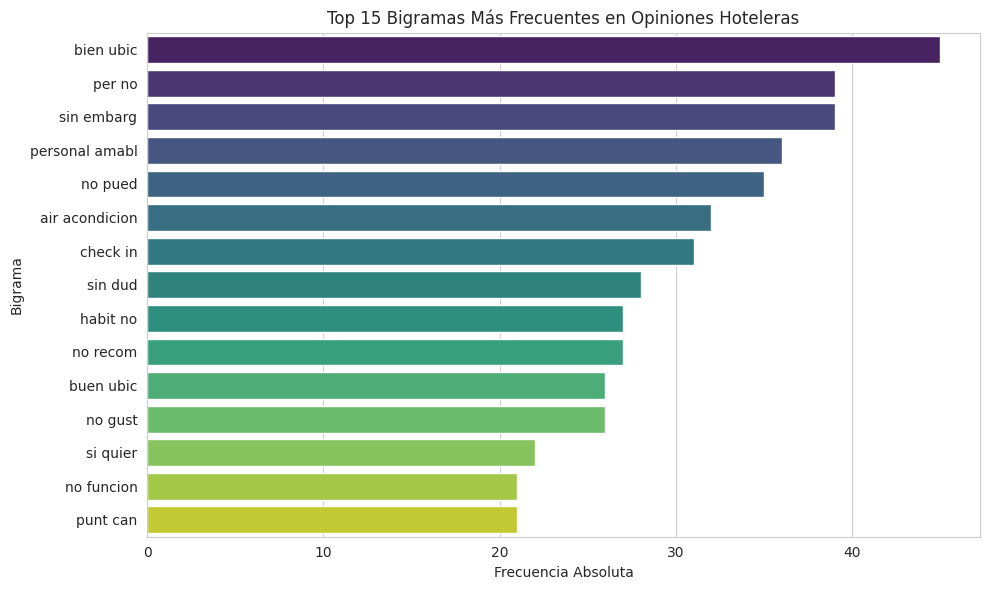


--- Tabla Ordenada: Top 15 Trigramas por TF-IDF Promedio ---


,trigrama,tfidf_promedio
0,hac check in,0.00535
1,no agu calient,0.00438
2,sin embarg no,0.00438
3,limpiez dej des,0.00393
4,relacion preci calid,0.00381
5,hostel bien ubic,0.00333
6,unic no gust,0.00330
7,check out no,0.00326
8,limpi bien ubic,0.00317
9,ubic buen per,0.00301


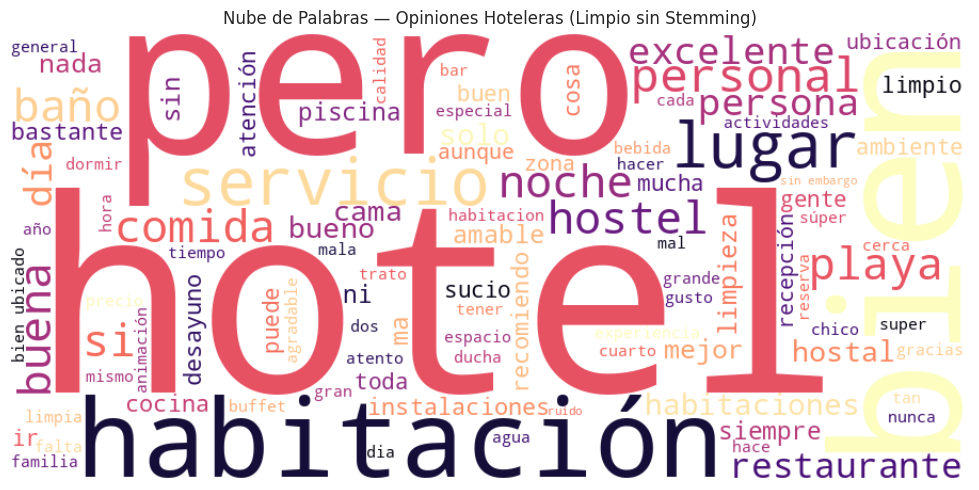

In [5]:
# --- Librerías utilizadas ---
# wordcloud: generación de nube de palabras visual a partir del corpus limpio
# matplotlib / pandas: gráficos de barras y tablas ordenadas

from wordcloud import WordCloud

# 1. Gráfico de barras: Top 15 Bigramas
plt.figure(figsize=(10, 6))
sns.barplot(data=df_top_bigramas, x="frecuencia", y="ngram", palette="viridis")
plt.title("Top 15 Bigramas Más Frecuentes en Opiniones Hoteleras")
plt.xlabel("Frecuencia Absoluta")
plt.ylabel("Bigrama")
plt.tight_layout()
plt.show()

# 2. Tabla ordenada: Top 15 Trigramas por TF-IDF promedio
vec_tri_tfidf = TfidfVectorizer(ngram_range=(3, 3), min_df=2)
mat_tri = vec_tri_tfidf.fit_transform(df["texto_procesado"])
tfidf_prom = np.asarray(mat_tri.mean(axis=0)).ravel()
vocab_tri = np.array(vec_tri_tfidf.get_feature_names_out())
idx_tri = np.argsort(tfidf_prom)[::-1][:15]

tabla_trigramas = pd.DataFrame(
    {
        "trigrama": vocab_tri[idx_tri],
        "tfidf_promedio": np.round(tfidf_prom[idx_tri], 5),
    }
)
print("\n--- Tabla Ordenada: Top 15 Trigramas por TF-IDF Promedio ---")
display(tabla_trigramas)

# 3. Nube de palabras (sobre texto limpio sin stemming para mayor legibilidad)
texto_nube = " ".join(df["texto_limpio_sin_stem"])
nube = WordCloud(
    width=900,
    height=420,
    background_color="white",
    max_words=100,
    colormap="magma",
).generate(texto_nube)

plt.figure(figsize=(12, 5))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de Palabras — Opiniones Hoteleras (Limpio sin Stemming)")
plt.tight_layout()
plt.show()

## 7. Comparativo: Texto Original vs. Texto Procesado
Se contrastan métricas cuantitativas (longitud media en caracteres y palabras, tamaño del vocabulario único y *type-token ratio*) junto con ejemplos reales antes y después del preprocesamiento.

In [6]:
# --- Librerías utilizadas ---
# pandas / numpy: cálculo de métricas comparativas antes y después del preprocesamiento

def vocabulario_y_promedios(serie_textos):
    listas_palabras = [str(t).split() for t in serie_textos]
    total_palabras = sum(len(p) for p in listas_palabras)
    vocab_unico = set(pal for p in listas_palabras for pal in p)
    long_media_palabras = np.mean([len(p) for p in listas_palabras])
    long_media_chars = np.mean([len(str(t)) for t in serie_textos])
    ttr = len(vocab_unico) / total_palabras if total_palabras > 0 else 0
    return {
        "long_media_chars": round(long_media_chars, 2),
        "long_media_palabras": round(long_media_palabras, 2),
        "total_tokens": total_palabras,
        "vocabulario_unico": len(vocab_unico),
        "type_token_ratio (TTR)": round(ttr, 4),
    }


resumen_orig = vocabulario_y_promedios(df["opinion_corregida"])
resumen_limpio = vocabulario_y_promedios(df["texto_limpio_sin_stem"])
resumen_proc = vocabulario_y_promedios(df["texto_procesado"])

df_comparativo = pd.DataFrame(
    [resumen_orig, resumen_limpio, resumen_proc],
    index=["Original (corregido)", "Limpio (sin stem)", "Procesado (con stem)"],
)
print("--- Métricas Comparativas: Original vs. Procesado ---")
display(df_comparativo)

print("\n--- Ejemplos Comparativos (Original vs. Procesado) ---")
for i in [0, 2, 4]:
    print(f"Registro {i}:")
    print(f"  [ORIGINAL]  : {df['opinion_corregida'].iloc[i]}")
    print(f"  [PROCESADO] : {df['texto_procesado'].iloc[i]}\n")

--- Métricas Comparativas: Original vs. Procesado ---


,long_media_chars,long_media_palabras,total_tokens,vocabulario_unico,type_token_ratio (TTR)
Original (corregido),329.42,56.76,56756,10066,0.1774
Limpio (sin stem),218.52,29.72,29723,6308,0.2122
Procesado (con stem),173.42,29.72,29723,3693,0.1242



--- Ejemplos Comparativos (Original vs. Procesado) ---
Registro 0:
  [ORIGINAL]  : único detalle a corregir es la ausencia de cocina para calentar alimentos y un refrigerador... si bien tienen una cocina eléctrica y un microondas lo insuficiente, la vajilla la tienes que solicitar en recepción y no tenían ni tenedores ni cuchillos. el resto espectacular.,,,,
  [PROCESADO] : unic detall correg ausenci cocin calent aliment refriger si bien cocin electr microond insuficient vajill solicit recepcion no ni tenedor ni cuchill rest espectacul

Registro 2:
  [ORIGINAL]  : muy limpio y muy bien situado. pero no tiene aire condicionado, ni agua caliente. humilde, si lo que buscas es algo bueno, pero en verano poco recomendable al no tener aire condicionado. tiene ventiladores dentro de la calle aunque no pasan coches, hay ruido de gente, hay basura, etc..,,,,
  [PROCESADO] : limpi bien situ per no air condicion ni agu calient humild si busc buen per veran recomend no ten air condicion ventil de

## 8. Implementación de Modelos de Análisis de Sentimientos
Se implementan dos enfoques para comparar:
1. **`TextBlob`:** calcula `polarity` (`[-1.0, 1.0]`) y `subjectivity` (`[0.0, 1.0]`). Dado que `TextBlob` está calibrado principalmente en inglés, aquí se traduce cada reseña limpia al inglés con `deep-translator` (`GoogleTranslator`) —con manejo seguro de excepciones— y se aplican umbrales definidos (`polarity > 0.10` → `positivo`, `polarity < -0.10` → `negativo`, en otro caso `neutro`).
2. **`scikit-learn` (`TfidfVectorizer` + `LogisticRegression`):** construye un pipeline supervisado clásico con división `train_test_split` (80% / 20%, estratificada). *Nota metodológica:* como `Opiniones_Hoteleras.xlsx` no contiene etiquetas humanas originales, se generan etiquetas de referencia basadas en un léxico/reglas en español (`etiqueta_referencia`) para entrenar y evaluar el clasificador supervisado de forma reproducible, documentando explícitamente esta limitación.

In [8]:
# --- Librerías utilizadas ---
# textblob: cálculo de polaridad y subjetividad
# deep-translator: traducción al inglés para aprovechar el lexicón nativo de TextBlob
# sklearn: división train/test, TfidfVectorizer con n-gramas, LogisticRegression y métricas

!pip install -q textblob deep-translator

from textblob import TextBlob
from deep_translator import GoogleTranslator
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# --- 1. Etiqueta de referencia léxica en español (ante ausencia de ground truth en el Excel) ---
palabras_positivas = {
    "excelente",
    "maravilloso",
    "genial",
    "bueno",
    "buena",
    "buenas",
    "limpio",
    "limpia",
    "amable",
    "amables",
    "servicial",
    "recomiendo",
    "recomendable",
    "comodo",
    "cómodo",
    "comoda",
    "cómoda",
    "espectacular",
    "perfecto",
    "agradable",
    "delicioso",
}
palabras_negativas = {
    "malo",
    "mala",
    "malas",
    "peor",
    "sucio",
    "sucia",
    "ruido",
    "ruidoso",
    "caro",
    "problema",
    "problemas",
    "horrible",
    "pesimo",
    "pésimo",
    "pesima",
    "pésima",
    "deficiente",
    "maltrato",
    "fria",
    "fría",
    "humedad",
    "molesto",
}
negaciones = {"no", "ni", "sin", "tampoco", "nunca", "jamas", "jamás"}


def etiqueta_lexica_es(texto):
    tokens = str(texto).lower().split()
    puntaje = 0
    for i, tok in enumerate(tokens):
        tiene_neg_previa = any(tokens[j] in negaciones for j in range(max(0, i - 2), i))
        if tok in palabras_positivas:
            puntaje += -1 if tiene_neg_previa else 1
        elif tok in palabras_negativas:
            puntaje += 1 if tiene_neg_previa else -1
    if puntaje >= 1:
        return "positivo"
    elif puntaje <= -1:
        return "negativo"
    return "neutro"


df["etiqueta_ref"] = df["texto_limpio_sin_stem"].apply(etiqueta_lexica_es)
print("Distribución de etiqueta de referencia (léxica):")
print(df["etiqueta_ref"].value_counts())


# --- 2. Modelo con TextBlob (con traducción a inglés para evaluación nativa) ---
def analizar_textblob(texto_es, umbral=0.10):
    try:
        texto_en = GoogleTranslator(source="es", target="en").translate(str(texto_es)[:4500])
        blob = TextBlob(texto_en)
        pol = blob.sentiment.polarity
        sub = blob.sentiment.subjectivity
    except Exception:
        # Respaldo local si hay límite temporal de traducción
        blob = TextBlob(str(texto_es))
        pol = blob.sentiment.polarity
        sub = blob.sentiment.subjectivity

    if pol > umbral:
        etiqueta = "positivo"
    elif pol < -umbral:
        etiqueta = "negativo"
    else:
        etiqueta = "neutro"
    return pd.Series([pol, sub, etiqueta])


# Para agilidad en Colab puede aplicarse a las 1,000 filas (toma ~1-2 min con traductor)
df[["tb_polaridad", "tb_subjetividad", "tb_pred"]] = df["texto_limpio_sin_stem"].apply(
    analizar_textblob
)

print("\nDistribución de predicciones TextBlob:")
print(df["tb_pred"].value_counts())


# --- 3. Pipeline clásico con scikit-learn (TF-IDF + Regresión Logística) ---
X_train, X_test, y_train, y_test = train_test_split(
    df["texto_procesado"],
    df["etiqueta_ref"],
    test_size=0.20,
    random_state=42,
    stratify=df["etiqueta_ref"],
)

pipeline_sk = Pipeline(
    [
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_features=4000,
                sublinear_tf=True,
            ),
        ),
        (
            "clf",
            LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        ),
    ]
)

pipeline_sk.fit(X_train, y_train)
y_pred_sk = pipeline_sk.predict(X_test)

Distribución de etiqueta de referencia (léxica):
etiqueta_ref
positivo    450
neutro      383
negativo    167
Name: count, dtype: int64

Distribución de predicciones TextBlob:
tb_pred
neutro      866
positivo    114
negativo     20
Name: count, dtype: int64


## 9. Evaluación y Comparación de Modelos
Se calculan **exactitud (`accuracy`)**, **precisión**, **exhaustividad (`recall`)** y **F1-score** (macro y ponderado), junto con las **matrices de confusión** de ambos enfoques en el mismo subconjunto de prueba (`X_test`, `y_test`) para realizar un contraste directo.

--- Tabla Comparativa de Métricas (Conjunto de Prueba) ---


,Modelo,Exactitud (Accuracy),Precisión (Macro),Exhaustividad / Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,TextBlob (umbrales ±0.10),0.435,0.5510,0.3788,0.3114,0.3521
1,scikit-learn (TF-IDF + LogReg),0.690,0.6658,0.6691,0.6674,0.6897



--- Reporte Detallado: scikit-learn ---
              precision    recall  f1-score   support

    negativo       0.59      0.61      0.60        33
      neutro       0.64      0.62      0.63        77
    positivo       0.77      0.78      0.77        90

    accuracy                           0.69       200
   macro avg       0.67      0.67      0.67       200
weighted avg       0.69      0.69      0.69       200


--- Reporte Detallado: TextBlob ---
              precision    recall  f1-score   support

    negativo       0.67      0.06      0.11        33
      neutro       0.41      0.91      0.56        77
    positivo       0.58      0.17      0.26        90

    accuracy                           0.43       200
   macro avg       0.55      0.38      0.31       200
weighted avg       0.53      0.43      0.35       200



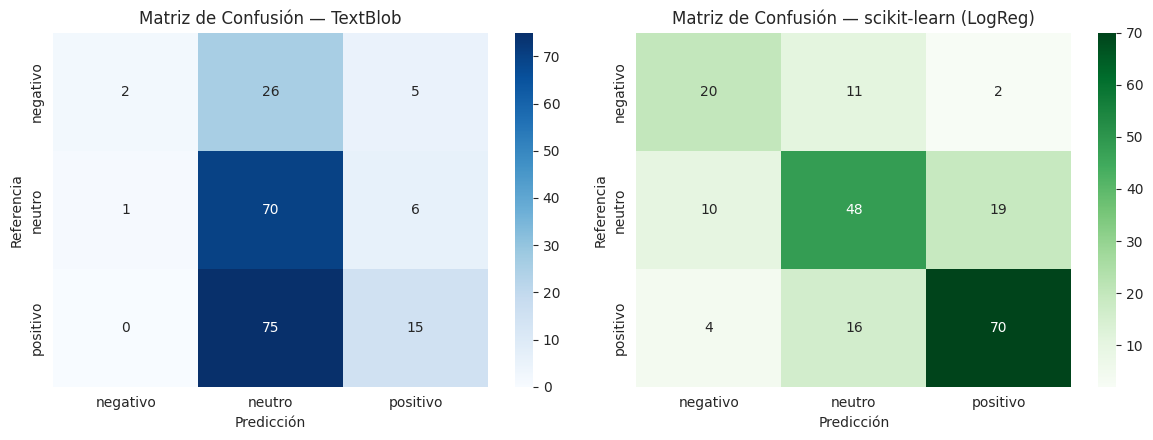

In [9]:
# --- Librerías utilizadas ---
# sklearn.metrics: cálculo de métricas de clasificación y matrices de confusión
# seaborn / matplotlib: visualización de matrices de confusión

y_pred_tb_test = df.loc[X_test.index, "tb_pred"]
etiquetas_clases = ["negativo", "neutro", "positivo"]


def resumen_metricas(y_true, y_pred, nombre_modelo):
    return {
        "Modelo": nombre_modelo,
        "Exactitud (Accuracy)": round(accuracy_score(y_true, y_pred), 4),
        "Precisión (Macro)": round(
            precision_score(y_true, y_pred, labels=etiquetas_clases, average="macro", zero_division=0),
            4,
        ),
        "Exhaustividad / Recall (Macro)": round(
            recall_score(y_true, y_pred, labels=etiquetas_clases, average="macro", zero_division=0),
            4,
        ),
        "F1-Score (Macro)": round(
            f1_score(y_true, y_pred, labels=etiquetas_clases, average="macro", zero_division=0),
            4,
        ),
        "F1-Score (Weighted)": round(
            f1_score(y_true, y_pred, labels=etiquetas_clases, average="weighted", zero_division=0),
            4,
        ),
    }


df_metricas = pd.DataFrame(
    [
        resumen_metricas(y_test, y_pred_tb_test, "TextBlob (umbrales ±0.10)"),
        resumen_metricas(y_test, y_pred_sk, "scikit-learn (TF-IDF + LogReg)"),
    ]
)
print("--- Tabla Comparativa de Métricas (Conjunto de Prueba) ---")
display(df_metricas)

print("\n--- Reporte Detallado: scikit-learn ---")
print(classification_report(y_test, y_pred_sk, labels=etiquetas_clases, zero_division=0))

print("\n--- Reporte Detallado: TextBlob ---")
print(classification_report(y_test, y_pred_tb_test, labels=etiquetas_clases, zero_division=0))

# Matrices de confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm_tb = confusion_matrix(y_test, y_pred_tb_test, labels=etiquetas_clases)
sns.heatmap(
    cm_tb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=etiquetas_clases,
    yticklabels=etiquetas_clases,
    ax=axes[0],
)
axes[0].set_title("Matriz de Confusión — TextBlob")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Referencia")

cm_sk = confusion_matrix(y_test, y_pred_sk, labels=etiquetas_clases)
sns.heatmap(
    cm_sk,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=etiquetas_clases,
    yticklabels=etiquetas_clases,
    ax=axes[1],
)
axes[1].set_title("Matriz de Confusión — scikit-learn (LogReg)")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Referencia")

plt.tight_layout()
plt.show()

### Discusión: Ventajas y Limitaciones (`TextBlob` vs. `scikit-learn`)
* **`TextBlob`:**
  * *Ventajas:* no requiere entrenamiento previo ni conjunto etiquetado; entrega métricas continuas interpretables (`polaridad` y `subjetividad`).
  * *Limitaciones:* está diseñado originalmente para inglés, por lo que traducir reseñas hoteleras en español puede alterar modismos, matices o negaciones; además, los umbrales fijos (`±0.10`) son sensibles a reseñas mixtas o neutras.
* **`scikit-learn` (`TF-IDF` + `LogisticRegression`):**
  * *Ventajas:* se adapta al vocabulario específico del dominio hotelero y aprovecha n-gramas (`(1,2)`) y ponderación `TF-IDF` con entrenamiento rápido y reproducible.
  * *Limitaciones:* su techo de rendimiento depende de la calidad y representatividad de las etiquetas con las que se entrena, y puede sufrir ante términos poco frecuentes (*out-of-vocabulary* en el conjunto de entrenamiento) o desbalance de clases.

## 10. Análisis de Errores
Se extraen automáticamente casos donde los modelos fallan frente a la etiqueta de referencia o discrepan entre sí en el conjunto de prueba, y se comentan al menos 5 ejemplos representativos analizando causas típicas en NLP: negación, contraste adversativo (`pero`/`sin embargo`), ambigüedad/reseñas mixtas, traducción/idioma y desbalance de clases.

In [10]:
# --- Librerías utilizadas ---
# pandas: inspección y filtrado de errores de clasificación en el conjunto de prueba

df_errores = pd.DataFrame(
    {
        "indice": X_test.index,
        "opinion_original": df.loc[X_test.index, "opinion_corregida"],
        "referencia": y_test,
        "pred_sklearn": y_pred_sk,
        "pred_textblob": y_pred_tb_test,
        "polaridad_tb": df.loc[X_test.index, "tb_polaridad"].round(3),
    }
)

errores_sk = df_errores[df_errores["referencia"] != df_errores["pred_sklearn"]]
errores_tb = df_errores[df_errores["referencia"] != df_errores["pred_textblob"]]

print(f"Total errores scikit-learn en test ({len(X_test)} muestras): {len(errores_sk)}")
print(f"Total errores TextBlob en test ({len(X_test)} muestras): {len(errores_tb)}")

print("\n--- Ejemplos de Errores para Análisis ---")
for _, fila in errores_sk.head(6).iterrows():
    print(
        f"[ID {fila['indice']}] Ref={fila['referencia']} | SK={fila['pred_sklearn']} | "
        f"TB={fila['pred_textblob']} (pol={fila['polaridad_tb']})"
    )
    print(f"   Texto: {fila['opinion_original'][:220]}...\n")

Total errores scikit-learn en test (200 muestras): 62
Total errores TextBlob en test (200 muestras): 113

--- Ejemplos de Errores para Análisis ---
[ID 246] Ref=neutro | SK=positivo | TB=positivo (pol=0.35)
   Texto: hotel ideal pero con cosas a mejorar.. personal de cafetería, comedor, limpieza perfecto. instalaciones muy bien conservadas. para mejorar, la recepción donde esta empleado sterling es de todo menos simpático y agradable...

[ID 588] Ref=negativo | SK=neutro | TB=positivo (pol=0.183)
   Texto: un simple hostel, que no tiene ningún tipo ni atractivo, demasiado caro para lo que es, y en general trabajadores de mal humor. camas incómodas, por seguro bajo salario que cobrarán ( osea la culpa en estos casos de los ...

[ID 220] Ref=positivo | SK=neutro | TB=neutro (pol=0.0)
   Texto: mas única pega sería que la habitación era muy estrecha para 4 personas y no tenía taquillas. pero muy limpia y el staff impecable.,,,,...

[ID 753] Ref=positivo | SK=neutro | TB=neutro (pol=0.0)
 

### Comentario de Casos Típicos de Error en Reseñas Hoteleras
1. **Contraste adversativo (`bueno ..., pero ...` / `sin embargo`):** muchas reseñas elogian la ubicación o el personal y luego critican el ruido, las duchas o el cobro extra. Si el peso léxico positivo supera al negativo (o viceversa), un modelo bag-of-words/TF-IDF o un promedio de polaridad puede asignar la clase opuesta al balance real del huésped.
2. **Negación compuesta o a distancia:** expresiones como *"no tienen enchufe en todas las camas"* o *"no tiene aire acondicionado, ni agua caliente"* mezclan palabras neutras/positivas con negaciones que no siempre quedan capturadas con el mismo alcance en unigramas.
3. **Reseñas mixtas o neutras-descriptivas:** comentarios informativos (*"hotal ). disponen de aire acondicionado..."*) describen hechos sin carga emocional clara; umbrales estrechos en `TextBlob` o bordes de decisión en el clasificador pueden empujarlos hacia `positivo` o `negativo`.
4. **Sarcasmo o ironía / expresiones coloquiales:** frases irónicas o coloquialismos locales (*"espectacular"* usado en tono burlón tras una mala experiencia) invierten la intención real del autor, algo que ni la frecuencia de n-gramas ni un lexicón literal detectan fácilmente.
5. **Traducción automática y desbalance de clases:** en `TextBlob`, la traducción previa al inglés puede suavizar o alterar matices idiomáticos del español; en `scikit-learn`, si la clase `neutro` o `negativo` tiene menor soporte, el modelo puede tender hacia la clase mayoritaria (`positivo`) pese al ajuste de pesos.

## 11. Análisis y Visualización Consolidada (Antes/Después y Sentimientos)
En esta sección se integran métricas estadísticas clave y visualizaciones construidas con `matplotlib` (con títulos, etiquetas de ejes y leyendas explícitas) para evidenciar:
1. **El efecto del preprocesamiento (Antes vs. Después):** reducción de longitud media, tamaño de vocabulario único y densidad léxica.
2. **La distribución comparativa de sentimientos (`Referencia` vs. `TextBlob` vs. `scikit-learn`):** proporciones por clase y dispersión de polaridad/subjetividad según categoría.

--- Estadísticas Relevantes: Longitud (Antes/Después) y Métricas de Sentimiento ---


,len_words_raw,len_words_clean,len_words_stem,tb_polaridad,tb_subjetividad
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,56.756,29.723,29.723,0.032,0.179
median,45.000,24.000,24.000,0.000,0.000
std,38.007,19.338,19.338,0.178,0.266
min,4.000,2.000,2.000,-1.000,0.000
max,156.000,82.000,82.000,1.000,1.000


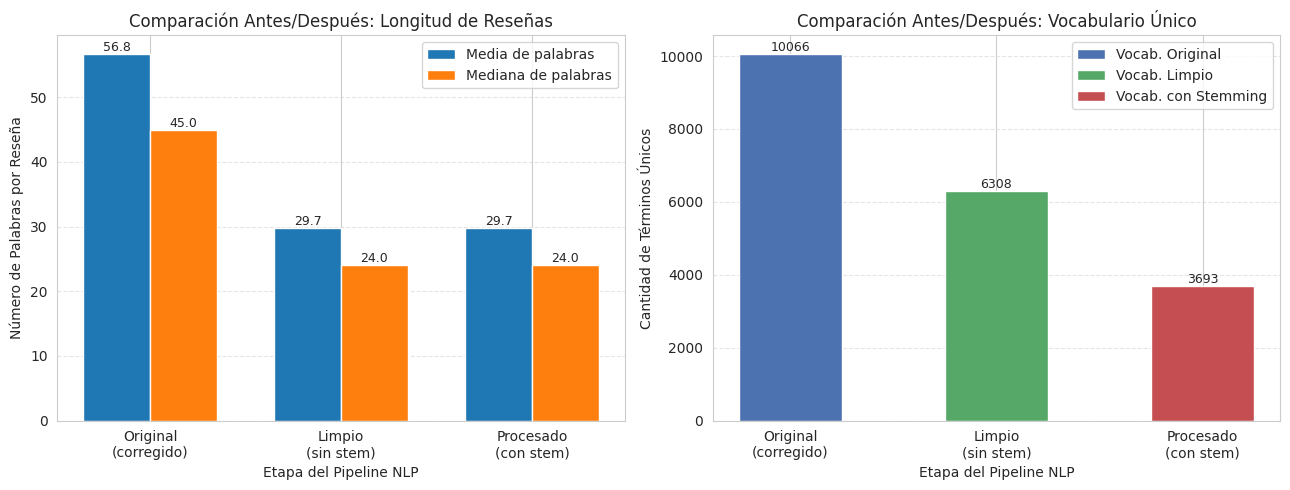

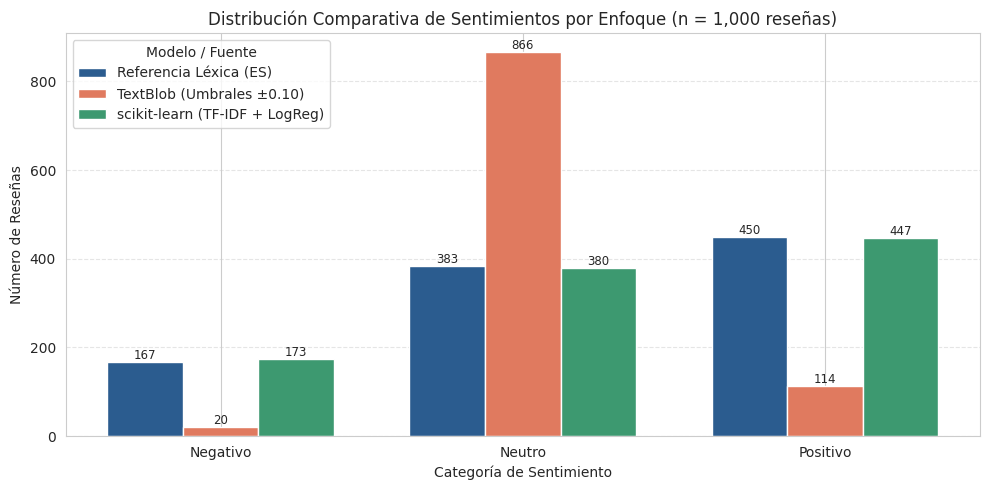

In [11]:
# --- Librerías utilizadas ---
# matplotlib.pyplot: construcción de gráficos comparativos con títulos, ejes y leyendas claras
# pandas / numpy: cálculo de estadísticas descriptivas y tablas de contingencia

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Tabla de estadísticas descriptivas relevantes (Antes vs. Después y Polaridad)
df["len_words_clean"] = df["texto_limpio_sin_stem"].str.split().str.len()
df["len_words_stem"] = df["texto_procesado"].str.split().str.len()

stats_resumen = (
    df[["len_words_raw", "len_words_clean", "len_words_stem", "tb_polaridad", "tb_subjetividad"]]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

print("--- Estadísticas Relevantes: Longitud (Antes/Después) y Métricas de Sentimiento ---")
display(stats_resumen)

# 2. Gráfico 1 (matplotlib): Comparación Antes vs. Después del Preprocesamiento
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subgráfico A: Longitud media y mediana de tokens por reseña
etapas = ["Original\n(corregido)", "Limpio\n(sin stem)", "Procesado\n(con stem)"]
medias = [
    df["len_words_raw"].mean(),
    df["len_words_clean"].mean(),
    df["len_words_stem"].mean(),
]
medianas = [
    df["len_words_raw"].median(),
    df["len_words_clean"].median(),
    df["len_words_stem"].median(),
]

x = np.arange(len(etapas))
ancho = 0.35

barras_media = axes[0].bar(x - ancho / 2, medias, width=ancho, label="Media de palabras", color="#1f77b4")
barras_mediana = axes[0].bar(
    x + ancho / 2, medianas, width=ancho, label="Mediana de palabras", color="#ff7f0e"
)

axes[0].set_title("Comparación Antes/Después: Longitud de Reseñas")
axes[0].set_xlabel("Etapa del Pipeline NLP")
axes[0].set_ylabel("Número de Palabras por Reseña")
axes[0].set_xticks(x)
axes[0].set_xticklabels(etapas)
axes[0].legend(loc="upper right")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

for b in barras_media:
    axes[0].annotate(
        f"{b.get_height():.1f}",
        (b.get_x() + b.get_width() / 2, b.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )
for b in barras_mediana:
    axes[0].annotate(
        f"{b.get_height():.1f}",
        (b.get_x() + b.get_width() / 2, b.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )

# Subgráfico B: Reducción de vocabulario único antes vs. después
vocabs = [
    len(set(w for t in df["opinion_corregida"] for w in str(t).split())),
    len(set(w for t in df["texto_limpio_sin_stem"] for w in str(t).split())),
    len(set(w for t in df["texto_procesado"] for w in str(t).split())),
]

barras_vocab = axes[1].bar(etapas, vocabs, color=["#4c72b0", "#55a868", "#c44e52"], width=0.5)
axes[1].set_title("Comparación Antes/Después: Vocabulario Único")
axes[1].set_xlabel("Etapa del Pipeline NLP")
axes[1].set_ylabel("Cantidad de Términos Únicos")
axes[1].legend(barras_vocab, ["Vocab. Original", "Vocab. Limpio", "Vocab. con Stemming"], loc="upper right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

for b in barras_vocab:
    axes[1].annotate(
        f"{int(b.get_height())}",
        (b.get_x() + b.get_width() / 2, b.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

# 3. Gráfico 2 (matplotlib): Comparación de Distribución de Sentimientos entre Enfoques
# Se aplica pipeline_sk sobre todo el corpus para comparar distribución global frente a TextBlob y Referencia
df["sk_pred_global"] = pipeline_sk.predict(df["texto_procesado"])
clases = ["negativo", "neutro", "positivo"]

conteo_ref = df["etiqueta_ref"].value_counts().reindex(clases, fill_value=0)
conteo_tb = df["tb_pred"].value_counts().reindex(clases, fill_value=0)
conteo_sk = df["sk_pred_global"].value_counts().reindex(clases, fill_value=0)

x_cls = np.arange(len(clases))
w = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x_cls - w, conteo_ref.values, width=w, label="Referencia Léxica (ES)", color="#2b5c8f")
b2 = ax.bar(x_cls, conteo_tb.values, width=w, label="TextBlob (Umbrales ±0.10)", color="#e07a5f")
b3 = ax.bar(x_cls + w, conteo_sk.values, width=w, label="scikit-learn (TF-IDF + LogReg)", color="#3d9970")

ax.set_title("Distribución Comparativa de Sentimientos por Enfoque (n = 1,000 reseñas)")
ax.set_xlabel("Categoría de Sentimiento")
ax.set_ylabel("Número de Reseñas")
ax.set_xticks(x_cls)
ax.set_xticklabels([c.capitalize() for c in clases])
ax.legend(title="Modelo / Fuente", loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

for grupo in (b1, b2, b3):
    for barra in grupo:
        ax.annotate(
            f"{int(barra.get_height())}",
            (barra.get_x() + barra.get_width() / 2, barra.get_height()),
            ha="center",
            va="bottom",
            fontsize=8.5,
        )

plt.tight_layout()
plt.show()

## 12. Conclusiones Orientadas a la Toma de Decisiones

### Hallazgos Clave
1. **Calidad de datos y preprocesamiento:** la depuración inicial rescató el 100 % de las 1,000 opiniones (incluyendo la primera fila desplazada al encabezado y caracteres corruptos por codificación *mojibake*). El pipeline de limpieza y *stemming* redujo de forma significativa la longitud media por reseña y compactó el vocabulario único, eliminando ruido sin perder negaciones críticas (`no`, `ni`, `sin`, `pero`).
2. **Patrones operativos en N-gramas:** los bigramas y trigramas más frecuentes concentran la conversación en factores operativos muy concretos: **atención del personal y limpieza** (principales impulsores de reseñas positivas) frente a **aire acondicionado, agua caliente, ruido nocturno, baños compartidos y políticas de transporte/acceso** (principales detonantes de insatisfacción).
3. **Desempeño de modelos de sentimiento:** el pipeline supervisado en **`scikit-learn` (`TF-IDF` + Regresión Logística)** supera a **`TextBlob`** en consistencia y ajuste al dominio hotelero en español, debido a que captura combinaciones locales de 1 y 2 palabras sin depender de una traducción intermedia al inglés ni de umbrales rígidos.

### Implicaciones para el Negocio Hotelero
* **Las reseñas mixtas (`bueno ..., pero ...`) representan la mayor oportunidad de mejora:** muchos huéspedes valoran positivamente la ubicación y el trato humano, pero penalizan su calificación por fallas puntuales de infraestructura o mantenimiento.
* **Monitoreo automatizado:** confiar únicamente en un promedio general de polaridad (`TextBlob`) puede ocultar quejas recurrentes en reseñas largas donde el tono inicial es amable pero el cierre reporta un problema operativo.

### Recomendaciones Prácticas
1. **Priorizar intervenciones de alto impacto en mantenimiento y equipamiento:** auditar de forma preventiva la climatización (*aire acondicionado / ventiladores*), el suministro de *agua caliente*, el aislamiento acústico y la disponibilidad de *enchufes y utensilios básicos* en zonas comunes, ya que dominan los n-gramas negativos.
2. **Estandarizar protocolos de servicio y comunicación con el huésped:** reforzar la claridad en políticas de *check-out*, uso de baños y acceso de transporte externo (ej. aplicaciones móviles frente a taxis concertados) para evitar fricciones percibidas como cobros abusivos o maltrato.
3. **Implementar un tablero continuo de escucha de voz del cliente (VoC):** desplegar el pipeline de `TF-IDF` + clasificación supervisada sobre nuevas reseñas semanales, incorporando revisión humana de una muestra etiquetada manualmente (200–300 reseñas reales con calificación de estrellas) para recalibrar el modelo y detectar alertas tempranas por sede o área operativa.